Running Quadratic Canyon experiment...


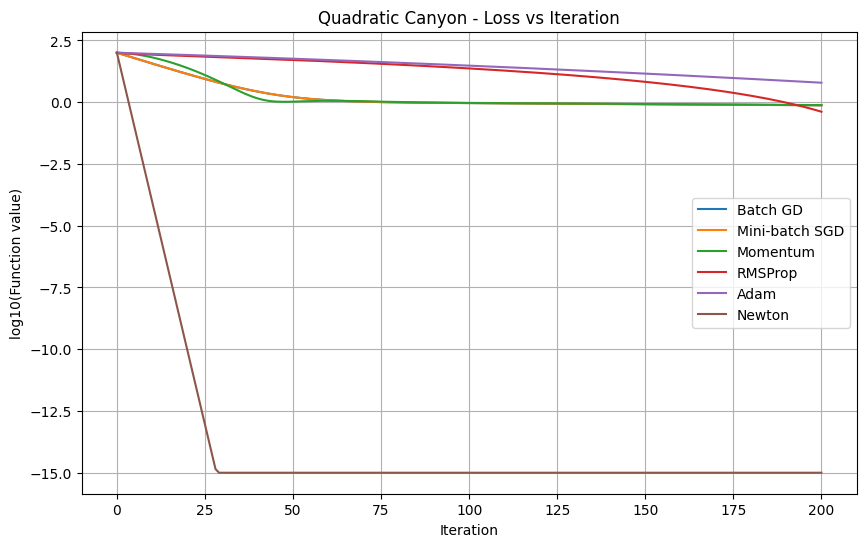

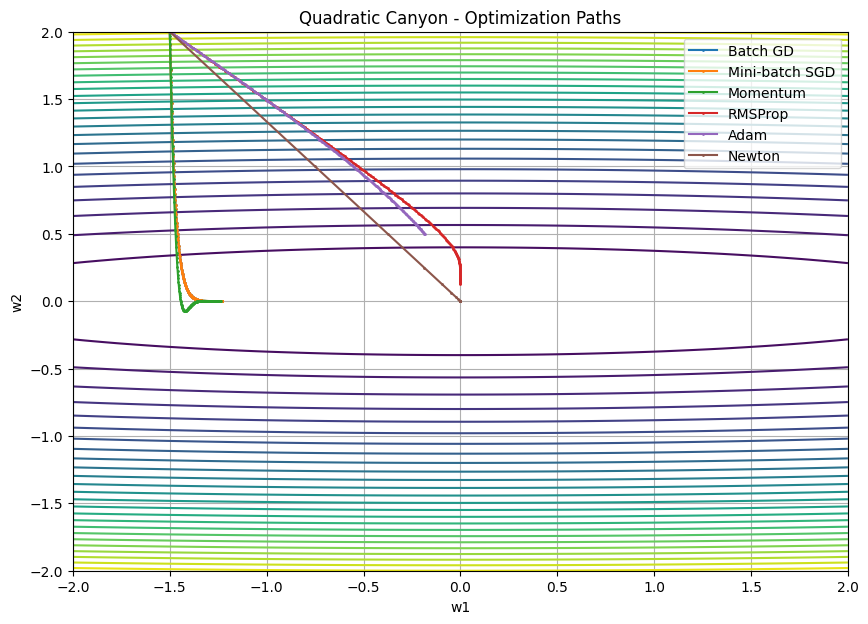

Running Rosenbrock experiment...


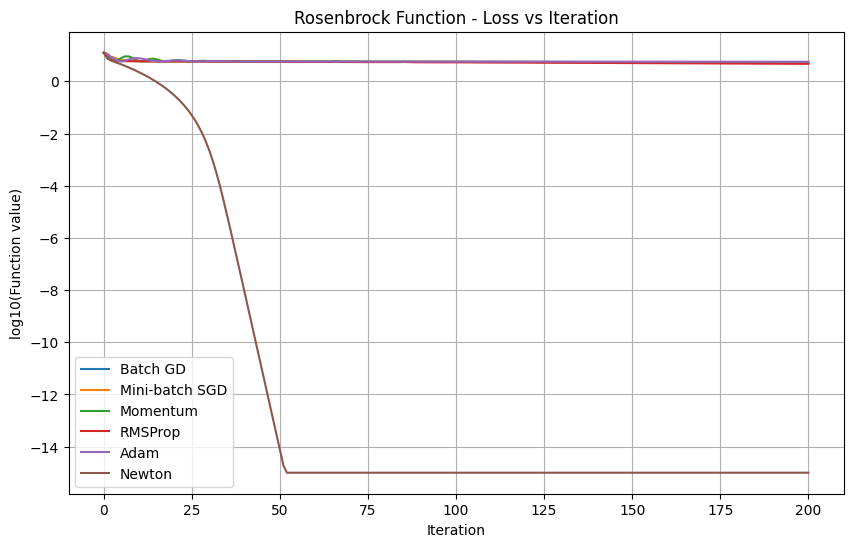

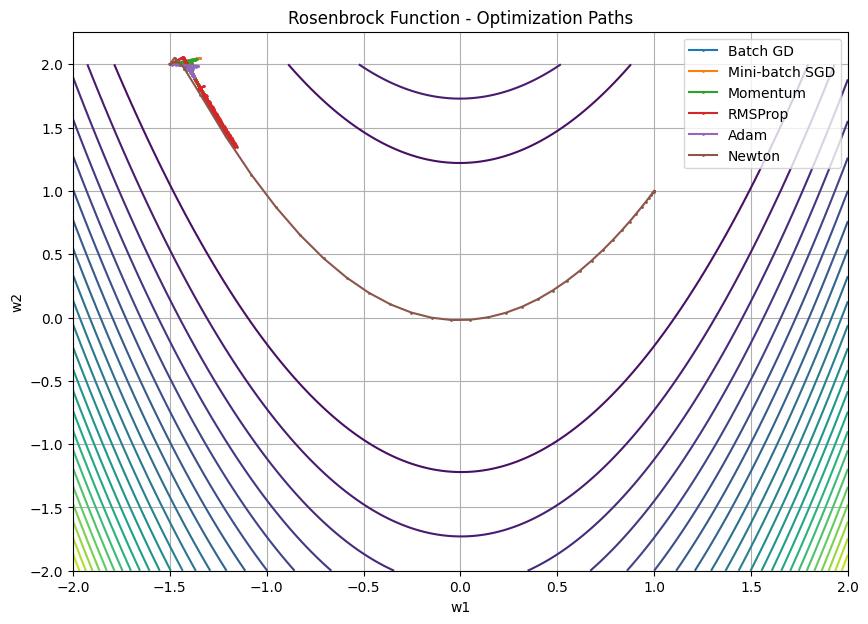

Experiments completed!


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import time
import tracemalloc

# ==========================================
# 1. OBJECTIVE FUNCTIONS
# ==========================================

def canyon(w):
    """Ill-conditioned quadratic function."""
    return 0.5 * w[0]**2 + 25 * w[1]**2

def canyon_gradient(w):
    return np.array([w[0], 50 * w[1]], dtype=float)


def rosenbrock(w):
    """Rosenbrock function."""
    x, y = w
    return (1 - x)**2 + 100 * (y - x**2)**2

def rosenbrock_gradient(w):
    x, y = w
    dx = -2 * (1 - x) - 400 * x * (y - x**2)
    dy = 200 * (y - x**2)
    return np.array([dx, dy], dtype=float)


# ==========================================
# 2. VANILLA BATCH GRADIENT DESCENT
# ==========================================

class BatchGD:
    def __init__(self, lr=0.001):
        self.lr = lr

    def step(self, w, grad):
        return w - self.lr * grad


# ==========================================
# 3. MINI-BATCH SGD
# ==========================================

class MiniBatchSGD:
    def __init__(self, lr=0.001):
        self.lr = lr

    def step(self, w, grad):
        return w - self.lr * grad


# ==========================================
# 4. MOMENTUM OPTIMIZER
# ==========================================

class MomentumOptimizer:
    def __init__(self, lr=0.001, beta=0.9):
        self.lr = lr
        self.beta = beta
        self.v = None

    def step(self, w, grad):
        if self.v is None:
            self.v = np.zeros_like(w)

        self.v = self.beta * self.v + (1 - self.beta) * grad
        return w - self.lr * self.v


# ==========================================
# 5. RMSPROP OPTIMIZER
# ==========================================

class RMSPropOptimizer:
    def __init__(self, lr=0.001, beta=0.9, epsilon=1e-8):
        self.lr = lr
        self.beta = beta
        self.epsilon = epsilon
        self.s = None

    def step(self, w, grad):
        if self.s is None:
            self.s = np.zeros_like(w)

        self.s = self.beta * self.s + (1 - self.beta) * grad**2

        return w - self.lr * grad / (np.sqrt(self.s) + self.epsilon)


# ==========================================
# 6. ADAM OPTIMIZER
# ==========================================

class AdamOptimizer:
    def __init__(self, lr=0.001, beta1=0.9,
                 beta2=0.999, epsilon=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon
        self.m = None
        self.v = None
        self.t = 0

    def step(self, w, grad):
        if self.m is None:
            self.m = np.zeros_like(w)
            self.v = np.zeros_like(w)

        self.t += 1

        self.m = self.beta1 * self.m + (1 - self.beta1) * grad
        self.v = self.beta2 * self.v + (1 - self.beta2) * grad**2

        # Bias correction
        m_hat = self.m / (1 - self.beta1**self.t)
        v_hat = self.v / (1 - self.beta2**self.t)

        return w - self.lr * m_hat / (np.sqrt(v_hat) + self.epsilon)


# ==========================================
# 7. NEWTON OPTIMIZER
# ==========================================

class NewtonOptimizer:
    def __init__(self, lr=1.0):
        self.lr = lr

    def step(self, w, grad, hessian=None):
        if hessian is None:
            raise ValueError("Newton optimizer requires a Hessian matrix.")

        direction = np.linalg.solve(hessian, grad)
        return w - self.lr * direction


# ==========================================
# 8. RUN AN OPTIMIZATION EXPERIMENT
# ==========================================

def run_optimizer(function, gradient, optimizer, initial_w, steps=200):
    w = np.array(initial_w, dtype=float)
    path = [w.copy()]
    losses = [function(w)]

    for _ in range(steps):
        grad = gradient(w)

        if isinstance(optimizer, NewtonOptimizer):
            # Hessian for the two functions used here
            if function == canyon:
                hessian = np.array([[1.0, 0.0],
                                    [0.0, 50.0]])
            else:
                x, y = w
                hessian = np.array([
                    [2 - 400*y + 1200*x**2, -400*x],
                    [-400*x, 200]
                ])

            w = optimizer.step(w, grad, hessian)
        else:
            w = optimizer.step(w, grad)

        path.append(w.copy())
        losses.append(function(w))

    return np.array(path), np.array(losses)


# ==========================================
# 9. COMPARE ALL SIX OPTIMIZERS
# ==========================================

optimizers = {
    "Batch GD": BatchGD(lr=0.001),
    "Mini-batch SGD": MiniBatchSGD(lr=0.001),
    "Momentum": MomentumOptimizer(lr=0.001),
    "RMSProp": RMSPropOptimizer(lr=0.01),
    "Adam": AdamOptimizer(lr=0.01),
    "Newton": NewtonOptimizer(lr=0.5)
}

def compare_optimizers(function, gradient, initial_w):
    results = {}

    for name, optimizer in optimizers.items():
        path, losses = run_optimizer(
            function, gradient, optimizer, initial_w, steps=200
        )
        results[name] = (path, losses)

    return results


# ==========================================
# 10. PLOT OPTIMIZATION RESULTS
# ==========================================

def plot_results(function, gradient, initial_w, title):
    results = compare_optimizers(function, gradient, initial_w)

    # Plot loss against iteration
    plt.figure(figsize=(10, 6))

    for name, (path, losses) in results.items():
        plt.plot(
            np.arange(len(losses)),
            np.log10(np.maximum(losses, 1e-15)),
            label=name
        )

    plt.xlabel("Iteration")
    plt.ylabel("log10(Function value)")
    plt.title(title + " - Loss vs Iteration")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Plot optimization paths
    x = np.linspace(-2, 2, 200)
    y = np.linspace(-2, 2, 200)
    X, Y = np.meshgrid(x, y)

    if function == canyon:
        Z = 0.5 * X**2 + 25 * Y**2
    else:
        Z = (1 - X)**2 + 100 * (Y - X**2)**2

    plt.figure(figsize=(10, 7))
    plt.contour(X, Y, Z, levels=30)

    for name, (path, losses) in results.items():
        plt.plot(path[:, 0], path[:, 1], marker=".", markersize=2,
                 label=name)

    plt.xlabel("w1")
    plt.ylabel("w2")
    plt.title(title + " - Optimization Paths")
    plt.legend()
    plt.grid(True)
    plt.show()

    return results


# ==========================================
# 11. EXPERIMENT 1: QUADRATIC CANYON
# ==========================================

print("Running Quadratic Canyon experiment...")

canyon_results = plot_results(
    canyon,
    canyon_gradient,
    initial_w=[-1.5, 2.0],
    title="Quadratic Canyon"
)


# ==========================================
# 12. EXPERIMENT 1: ROSENBROCK FUNCTION
# ==========================================

print("Running Rosenbrock experiment...")

rosenbrock_results = plot_results(
    rosenbrock,
    rosenbrock_gradient,
    initial_w=[-1.5, 2.0],
    title="Rosenbrock Function"
)

print("Experiments completed!")

In [25]:
def compare_optimizers(function, gradient, initial_w):
    fresh_optimizers = {
        "Batch GD": BatchGD(lr=0.001),
        "Mini-batch SGD": MiniBatchSGD(lr=0.001),
        "Momentum": MomentumOptimizer(lr=0.001),
        "RMSProp": RMSPropOptimizer(lr=0.01),
        "Adam": AdamOptimizer(lr=0.01),
        "Newton": NewtonOptimizer(lr=0.5)
    }

    results = {}

    for name, optimizer in fresh_optimizers.items():
        path, losses = run_optimizer(
            function, gradient, optimizer, initial_w, steps=200
        )
        results[name] = (path, losses)

    return results


Dataset created!
Samples: 50000
Features: 50
Training: Batch GD
Training: Mini-batch SGD
Training: Momentum
Training: RMSProp
Training: Adam

All training experiments completed!


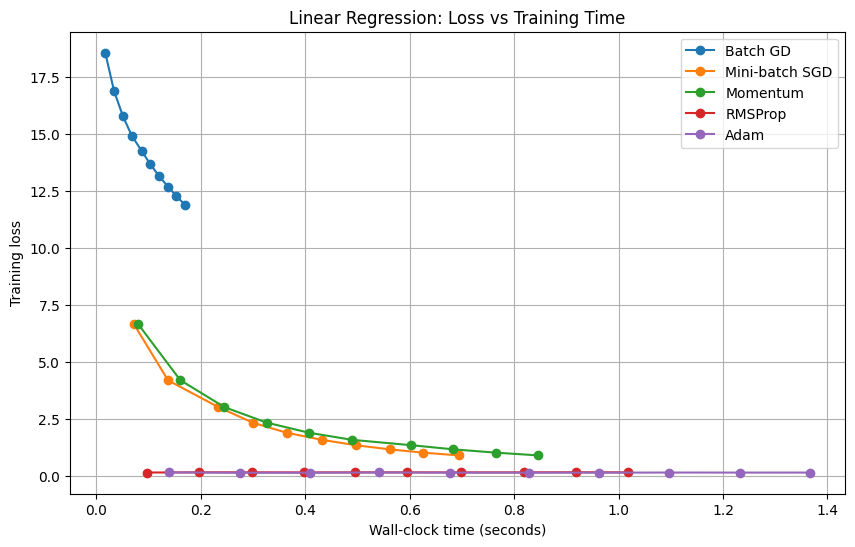

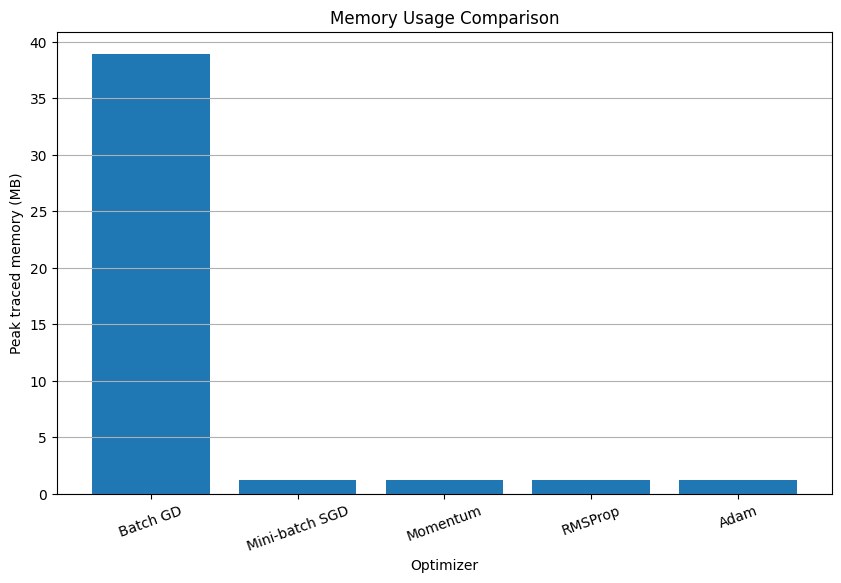


FINAL RESULTS
-----------------------------------------------------------------
Optimizer            Final Loss      Time (sec)   Memory MB
-----------------------------------------------------------------
Batch GD             11.885516       0.170        38.917
Mini-batch SGD       0.888159        0.695        1.244
Momentum             0.888502        0.846        1.245
RMSProp              0.143654        1.017        1.245
Adam                 0.135305        1.366        1.245
-----------------------------------------------------------------


In [26]:
# ==========================================
# EXPERIMENT 2: LINEAR REGRESSION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import time
import tracemalloc

# 1. Create dataset: 50,000 samples and 50 features

np.random.seed(42)

N = 50000
features = 50

scales = np.geomspace(0.2, 5.0, features)

X = np.random.randn(N, features) * scales

true_weights = np.random.randn(features) / scales
y = X @ true_weights + np.random.randn(N) * 0.5

print("Dataset created!")
print("Samples:", N)
print("Features:", features)


# 2. Define loss and gradient

def calculate_loss(X, y, w):
    error = X @ w - y
    return np.mean(error ** 2) / 2


def calculate_gradient(X, y, w):
    error = X @ w - y
    return (X.T @ error) / len(y)


# 3. Training function

def train_model(name, optimizer, batch_size, epochs=10):

    w = np.zeros(features)
    losses = []
    elapsed_times = []

    tracemalloc.start()
    start_time = time.perf_counter()

    for epoch in range(epochs):

        indices = np.random.permutation(N)

        # Full batch or mini-batch training
        if batch_size == N:
            batches = [indices]
        else:
            batches = [
                indices[i:i + batch_size]
                for i in range(0, N, batch_size)
            ]

        for batch in batches:
            X_batch = X[batch]
            y_batch = y[batch]

            grad = calculate_gradient(X_batch, y_batch, w)
            w = optimizer.step(w, grad)

        current_loss = calculate_loss(X, y, w)

        losses.append(current_loss)
        elapsed_times.append(time.perf_counter() - start_time)

    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    total_time = time.perf_counter() - start_time

    return {
        "weights": w,
        "losses": losses,
        "times": elapsed_times,
        "total_time": total_time,
        "memory": peak_memory / (1024 ** 2)
    }


# 4. Compare five optimizers

experiments = {
    "Batch GD": (BatchGD(lr=0.02), N),
    "Mini-batch SGD": (MiniBatchSGD(lr=0.001), 64),
    "Momentum": (MomentumOptimizer(lr=0.001), 64),
    "RMSProp": (RMSPropOptimizer(lr=0.01), 64),
    "Adam": (AdamOptimizer(lr=0.01), 64)
}

results = {}

for name, (optimizer, batch_size) in experiments.items():

    print("Training:", name)

    results[name] = train_model(
        name, optimizer, batch_size, epochs=10
    )

print("\nAll training experiments completed!")


# 5. Plot loss against wall-clock time

plt.figure(figsize=(10, 6))

for name, result in results.items():
    plt.plot(
        result["times"],
        result["losses"],
        marker="o",
        label=name
    )

plt.xlabel("Wall-clock time (seconds)")
plt.ylabel("Training loss")
plt.title("Linear Regression: Loss vs Training Time")
plt.legend()
plt.grid(True)
plt.show()


# 6. Compare memory usage

names = list(results.keys())
memory = [results[name]["memory"] for name in names]

plt.figure(figsize=(10, 6))
plt.bar(names, memory)

plt.xlabel("Optimizer")
plt.ylabel("Peak traced memory (MB)")
plt.title("Memory Usage Comparison")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()


# 7. Print final comparison table

print("\nFINAL RESULTS")
print("-" * 65)
print(f"{'Optimizer':<20} {'Final Loss':<15} {'Time (sec)':<12} {'Memory MB'}")
print("-" * 65)

for name, result in results.items():
    print(
        f"{name:<20} "
        f"{result['losses'][-1]:<15.6f} "
        f"{result['total_time']:<12.3f} "
        f"{result['memory']:.3f}"
    )

print("-" * 65)


In [27]:
# ==========================================
# CORRECTNESS TEST: GRADIENT CHECK
# ==========================================

def numerical_gradient(function, w, h=1e-6):
    grad = np.zeros_like(w)

    for i in range(len(w)):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[i] += h
        w_minus[i] -= h

        grad[i] = (
            function(w_plus) - function(w_minus)
        ) / (2 * h)

    return grad


test_point = np.array([0.5, -0.3])

for name, function, gradient in [
    ("Canyon", canyon, canyon_gradient),
    ("Rosenbrock", rosenbrock, rosenbrock_gradient)
]:
    analytical = gradient(test_point)
    numerical = numerical_gradient(function, test_point)

    print("\n", name)
    print("Analytical gradient:", analytical)
    print("Numerical gradient: ", numerical)

    assert np.allclose(
        analytical, numerical, rtol=1e-4, atol=1e-5
    ), name + " gradient test failed!"

print("\nAll gradient tests passed!")


 Canyon
Analytical gradient: [  0.5 -15. ]
Numerical gradient:  [  0.5 -15. ]

 Rosenbrock
Analytical gradient: [ 109. -110.]
Numerical gradient:  [ 109. -110.]

All gradient tests passed!


In [28]:
# ==========================================
# OPTIMIZER CORRECTNESS TESTS
# ==========================================

w = np.array([2.0, 3.0])
grad = np.array([1.0, 2.0])
lr = 0.01

# Test Batch GD
gd = BatchGD(lr)
assert np.allclose(gd.step(w, grad), [1.99, 2.98])

# Test Mini-batch SGD
sgd = MiniBatchSGD(lr)
assert np.allclose(sgd.step(w, grad), [1.99, 2.98])

# Test Momentum
momentum = MomentumOptimizer(lr=lr, beta=0.9)
assert np.allclose(momentum.step(w, grad), [1.999, 2.998])

# Test RMSProp
rms = RMSPropOptimizer(lr=lr, beta=0.9)
rms_result = rms.step(w, grad)
assert np.all(np.isfinite(rms_result))

# Test Adam
adam = AdamOptimizer(lr=lr)
adam_result = adam.step(w, grad)
assert np.all(np.isfinite(adam_result))

# Test Newton
newton = NewtonOptimizer(lr=1.0)
H = np.array([[2.0, 0.0], [0.0, 4.0]])
newton_result = newton.step(w, grad, H)
assert np.allclose(newton_result, [1.5, 2.5])

print("Batch GD: PASSED")
print("Mini-batch SGD: PASSED")
print("Momentum: PASSED")
print("RMSProp: PASSED")
print("Adam: PASSED")
print("Newton: PASSED")
print("\nALL SIX OPTIMIZER TESTS PASSED!")


Batch GD: PASSED
Mini-batch SGD: PASSED
Momentum: PASSED
RMSProp: PASSED
Adam: PASSED
Newton: PASSED

ALL SIX OPTIMIZER TESTS PASSED!


In [29]:
# ==========================================
# PART A: QUESTION 1 - VANILLA GRADIENT DESCENT
# ==========================================

import numpy as np

eta = 0.18
w = np.array([4.0, 1.0])

def gradient(w):
    return np.array([w[0], 10 * w[1]])

print("QUESTION 1: VANILLA GRADIENT DESCENT")

for t in range(1, 3):
    g = gradient(w)
    w = w - eta * g

    print(f"\nStep {t}")
    print("Gradient:", g)
    print("New weights:", w)

# Learning rate 0.25
w = np.array([4.0, 1.0])
eta = 0.25
g = gradient(w)
new_w = w - eta * g

print("\nLearning rate = 0.25")
print("New weights:", new_w)


# ==========================================
# PART A: QUESTION 2 - MOMENTUM
# ==========================================

print("\nQUESTION 2: MOMENTUM")

eta = 0.18
beta = 0.5

w = np.array([4.0, 1.0])
v = np.array([0.0, 0.0])

for t in range(1, 3):
    g = gradient(w)

    v = beta * v + (1 - beta) * g
    w = w - eta * v

    print(f"\nStep {t}")
    print("Gradient:", g)
    print("Velocity:", v)
    print("New weights:", w)

print("\nPART A CALCULATIONS COMPLETED!")

QUESTION 1: VANILLA GRADIENT DESCENT

Step 1
Gradient: [ 4. 10.]
New weights: [ 3.28 -0.8 ]

Step 2
Gradient: [ 3.28 -8.  ]
New weights: [2.6896 0.64  ]

Learning rate = 0.25
New weights: [ 3.  -1.5]

QUESTION 2: MOMENTUM

Step 1
Gradient: [ 4. 10.]
Velocity: [2. 5.]
New weights: [3.64 0.1 ]

Step 2
Gradient: [3.64 1.  ]
Velocity: [2.82 3.  ]
New weights: [ 3.1324 -0.44  ]

PART A CALCULATIONS COMPLETED!


In [30]:
# ==========================================
# PART A: QUESTIONS 3, 4, 5 AND 6
# ==========================================

import numpy as np

# ==========================================
# QUESTION 3: RMSProp AND ADAM
# ==========================================

print("=" * 50)
print("QUESTION 3: RMSProp AND ADAM")
print("=" * 50)

w = np.array([4.0, 1.0])
g = np.array([4.0, 10.0])

eta = 0.5
beta1 = 0.9
beta2 = 0.9
epsilon = 0.0

# RMSProp
s = (1 - beta2) * (g ** 2)

w_rms = w - eta * g / np.sqrt(s + epsilon)

print("\nRMSProp:")
print("Gradient:", g)
print("Squared gradient accumulator:", s)
print("Updated weights:", w_rms)

# Adam
m = (1 - beta1) * g
s = (1 - beta2) * (g ** 2)

m_hat = m / (1 - beta1)
s_hat = s / (1 - beta2)

w_adam = w - eta * m_hat / np.sqrt(s_hat + epsilon)

print("\nAdam:")
print("First moment:", m)
print("Second moment:", s)
print("Corrected first moment:", m_hat)
print("Corrected second moment:", s_hat)
print("Updated weights:", w_adam)


# ==========================================
# QUESTION 4: ADAM BIAS CORRECTION
# ==========================================

print("\n" + "=" * 50)
print("QUESTION 4: ADAM BIAS CORRECTION")
print("=" * 50)

g1 = 10
beta1 = 0.99
m0 = 0

m1 = beta1 * m0 + (1 - beta1) * g1

m1_corrected = m1 / (1 - beta1)

print("Initial first moment:", m0)
print("Gradient:", g1)
print("Uncorrected moment:", m1)
print("Bias-corrected moment:", m1_corrected)


# ==========================================
# QUESTION 5: NEWTON'S METHOD
# ==========================================

print("\n" + "=" * 50)
print("QUESTION 5: NEWTON'S METHOD")
print("=" * 50)

w = np.array([4.0, 1.0])

g = np.array([4.0, 10.0])

H = np.array([
    [1.0, 0.0],
    [0.0, 10.0]
])

H_inverse = np.linalg.inv(H)

newton_step = H_inverse @ g

w_new = w - newton_step

print("Initial weights:", w)
print("Gradient:", g)
print("Hessian:\n", H)
print("Inverse Hessian:\n", H_inverse)
print("Newton step:", newton_step)
print("Updated weights:", w_new)


# Square root of 2 using Newton's method

print("\nSquare root of 2:")

x = 1.0

for i in range(2):
    x = 0.5 * (x + 2 / x)
    print(f"Step {i + 1}: {x}")


# ==========================================
# QUESTION 6: DATA STRUCTURES AND COMPLEXITY
# ==========================================

print("\n" + "=" * 65)
print("QUESTION 6: DATA STRUCTURES AND COMPLEXITY")
print("=" * 65)

methods = [
    ("Batch GD", "Theta(N*d)", "0"),
    ("Mini-batch SGD", "Theta(b*d)", "0"),
    ("Momentum", "Theta(b*d)", "d"),
    ("RMSProp", "Theta(b*d)", "d"),
    ("Adam", "Theta(b*d)", "2*d"),
    ("Newton", "Theta(d^3)", "Theta(d^2)")
]

print(f"{'Method':<20} {'Time per step':<20} {'Extra memory'}")
print("-" * 65)

for method, time_cost, memory in methods:
    print(f"{method:<20} {time_cost:<20} {memory}")

print("\nAll questions Q3, Q4, Q5 and Q6 completed!")

QUESTION 3: RMSProp AND ADAM

RMSProp:
Gradient: [ 4. 10.]
Squared gradient accumulator: [ 1.6 10. ]
Updated weights: [ 2.41886117 -0.58113883]

Adam:
First moment: [0.4 1. ]
Second moment: [ 1.6 10. ]
Corrected first moment: [ 4. 10.]
Corrected second moment: [ 16. 100.]
Updated weights: [3.5 0.5]

QUESTION 4: ADAM BIAS CORRECTION
Initial first moment: 0
Gradient: 10
Uncorrected moment: 0.10000000000000009
Bias-corrected moment: 10.0

QUESTION 5: NEWTON'S METHOD
Initial weights: [4. 1.]
Gradient: [ 4. 10.]
Hessian:
 [[ 1.  0.]
 [ 0. 10.]]
Inverse Hessian:
 [[1.  0. ]
 [0.  0.1]]
Newton step: [4. 1.]
Updated weights: [0. 0.]

Square root of 2:
Step 1: 1.5
Step 2: 1.4166666666666665

QUESTION 6: DATA STRUCTURES AND COMPLEXITY
Method               Time per step        Extra memory
-----------------------------------------------------------------
Batch GD             Theta(N*d)           0
Mini-batch SGD       Theta(b*d)           0
Momentum             Theta(b*d)           d
RMSProp     